# Bicubic Image Interpolation (NumPy Only)
**Objective:** Implement **Bicubic Interpolation** from scratch using **NumPy** to upscale a low-resolution grayscale image and compare it visually and quantitatively against Nearest-Neighbor and Bilinear interpolation.

### Mathematical Formulation
Bicubic interpolation estimates the pixel intensity at a continuous coordinate $(x, y)$ using a $4 \times 4$ neighborhood of surrounding pixels ($16$ neighbors) via the **Keys Cubic Convolution Kernel** ($a = -0.5$):

$$W(d) = \begin{cases}
(a + 2)|d|^3 - (a + 3)|d|^2 + 1, & |d| \le 1 \\
a|d|^3 - 5a|d|^2 + 8a|d| - 4a, & 1 < |d| < 2 \\
0, & |d| \ge 2
\end{cases}$$

The interpolated output intensity is the separable 2D weighted sum:
$$\hat{I}(x, y) = \sum_{m=-1}^{2} \sum_{n=-1}^{2} I(\lfloor x \rfloor + m, \lfloor y \rfloor + n) \cdot W(x - (\lfloor x \rfloor + m)) \cdot W(y - (\lfloor y \rfloor + n))$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a crisp 256x256 ground-truth image and downsample it to 64x64
N_high = 256
N_low = 64
x = np.linspace(-1, 1, N_high)
X, Y = np.meshgrid(x, x)

high_res = np.zeros((N_high, N_high), dtype=np.float32)
high_res[(X**2 + Y**2) < 0.45] = 0.85                                    # Circle
high_res[(np.abs(X - 0.3) < 0.18) & (np.abs(Y - 0.3) < 0.18)] = 0.45     # Square
high_res[30:50, 30:225] = 1.0                                            # Horizontal bar
high_res[30:225, 30:50] = 1.0                                            # Vertical bar

# Subsample 4x to create a 64x64 low-resolution input image
step = N_high // N_low
low_res = high_res[::step, ::step]


# 2. Keys Cubic Convolution Kernel (a = -0.5)
def cubic_kernel(d: np.ndarray, a: float = -0.5) -> np.ndarray:
    abs_d = np.abs(d)
    abs_d2 = abs_d ** 2
    abs_d3 = abs_d ** 3

    weights = np.where(
        abs_d <= 1.0,
        (a + 2.0) * abs_d3 - (a + 3.0) * abs_d2 + 1.0,
        np.where(
            abs_d < 2.0,
            a * abs_d3 - 5.0 * a * abs_d2 + 8.0 * a * abs_d - 4.0 * a,
            0.0
        )
    )
    return weights


# 3. Vectorized 2D Bicubic Interpolation (Pure NumPy)
def bicubic_resize_numpy(image: np.ndarray, new_h: int, new_w: int, a: float = -0.5) -> np.ndarray:
    H, W = image.shape
    # Pad border by 2 pixels so 4x4 neighborhoods never go out of bounds
    padded = np.pad(image, pad_width=2, mode="edge")

    # Map output pixel centers back to input coordinate space
    scale_y = H / new_h
    scale_x = W / new_w
    y = (np.arange(new_h) + 0.5) * scale_y - 0.5
    x = (np.arange(new_w) + 0.5) * scale_x - 0.5

    y0 = np.floor(y).astype(np.int32)
    x0 = np.floor(x).astype(np.int32)
    dy = y - y0  # Fractional offset in [0, 1)
    dx = x - x0

    # Compute 1D cubic weights for the 4 taps (-1, 0, 1, 2)
    offsets = np.array([-1, 0, 1, 2], dtype=np.float32)
    wy = cubic_kernel(dy[:, None] - offsets[None, :], a=a)  # Shape: (new_h, 4)
    wx = cubic_kernel(dx[:, None] - offsets[None, :], a=a)  # Shape: (new_w, 4)

    # Accumulate separable 4x4 weighted sum
    out = np.zeros((new_h, new_w), dtype=np.float32)
    for m_idx, m in enumerate([-1, 0, 1, 2]):
        row_indices = y0 + m + 2  # +2 accounts for border padding
        for n_idx, n in enumerate([-1, 0, 1, 2]):
            col_indices = x0 + n + 2
            patch = padded[row_indices[:, None], col_indices[None, :]]
            out += patch * (wy[:, m_idx][:, None] * wx[:, n_idx][None, :])

    return np.clip(out, 0.0, 1.0)


# 4. Reference Nearest-Neighbor & Bilinear Resizing for Comparison
def nearest_resize_numpy(image: np.ndarray, new_h: int, new_w: int) -> np.ndarray:
    H, W = image.shape
    y = np.clip(np.floor((np.arange(new_h) + 0.5) * (H / new_h)).astype(int), 0, H - 1)
    x = np.clip(np.floor((np.arange(new_w) + 0.5) * (W / new_w)).astype(int), 0, W - 1)
    return image[y[:, None], x[None, :]]


def bilinear_resize_numpy(image: np.ndarray, new_h: int, new_w: int) -> np.ndarray:
    H, W = image.shape
    y = np.clip((np.arange(new_h) + 0.5) * (H / new_h) - 0.5, 0, H - 1)
    x = np.clip((np.arange(new_w) + 0.5) * (W / new_w) - 0.5, 0, W - 1)

    y0 = np.floor(y).astype(int)
    x0 = np.floor(x).astype(int)
    y1 = np.minimum(y0 + 1, H - 1)
    x1 = np.minimum(x0 + 1, W - 1)

    wy = (y - y0)[:, None]
    wx = (x - x0)[None, :]

    top = image[y0[:, None], x0[None, :]] * (1 - wx) + image[y0[:, None], x1[None, :]] * wx
    bot = image[y1[:, None], x0[None, :]] * (1 - wx) + image[y1[:, None], x1[None, :]] * wx
    return top * (1 - wy) + bot * wy


# Upscale 64x64 -> 256x256 (4x zoom)
up_nearest  = nearest_resize_numpy(low_res, N_high, N_high)
up_bilinear = bilinear_resize_numpy(low_res, N_high, N_high)
up_bicubic  = bicubic_resize_numpy(low_res, N_high, N_high)

print(f"Input shape: {low_res.shape} -> Upscaled shape: {up_bicubic.shape}")

Input shape: (64, 64) -> Upscaled shape: (256, 256)


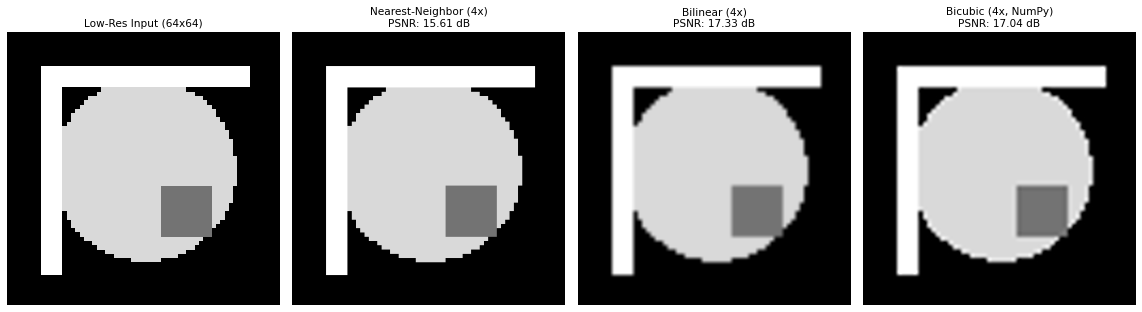

In [2]:
def compute_psnr(gt: np.ndarray, pred: np.ndarray) -> float:
    mse = np.mean((gt - pred) ** 2)
    return 10.0 * np.log10(1.0 / (mse + 1e-12))

panels = [
    ("Low-Res Input (64x64)", low_res, None),
    ("Nearest-Neighbor (4x)", up_nearest, compute_psnr(high_res, up_nearest)),
    ("Bilinear (4x)", up_bilinear, compute_psnr(high_res, up_bilinear)),
    ("Bicubic (4x, NumPy)", up_bicubic, compute_psnr(high_res, up_bicubic)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (title, im, psnr_val) in zip(axes, panels):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    label = f"{title}\nPSNR: {psnr_val:.2f} dB" if psnr_val is not None else title
    ax.set_title(label, fontsize=10.5)
    ax.axis("off")

plt.tight_layout()
plt.show()